In [1]:
import QAOAmc_core_components as core
import standard_QAOAmc as stdQAOAmc
import nonvariational_QWOAmc
import pretrained_QAOAmc as ptQAOAmc
import qiskit_aer
# File with plotting functions
import results_plotter as rp
import results_plotter_2 as rp2
# other relevant modules
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import expm
import networkx as nx
import bisect
import os
from scipy import stats

## Define Required Functions

#### Functions for converting between binary and integers:

In [2]:

def to_binary(x, bits):
    # Convert the integer to binary, fill with leading zeros, and reverse the order
    return np.array([int(i) for i in bin(x)[2:].zfill(bits)][::-1])
def to_int(x):
    # Reverse the order of the bits to convert back to normal binary representation
    return int(''.join([str(i) for i in x[::-1]]), 2)

#### Define the Hamming Distance:

In [3]:
def hamming_distance(partition1, partition2):
    # Calculate the Hamming distance
    distance = sum(v1 != v2 for v1, v2 in zip(partition1, partition2))
    return distance

#### Define Standard QAOA:
Uses random parameter initilisation, and the QAOA package which I built. This function will be used to empericically demonstrate that the considered instances of QAOA suffer from the BP

In [4]:
def Standard_QAOA(G,n,p):
    Q,qc,gamma_parameters,time_parameters = QAOA.set_up_sim(n,p,G)
    
    # Reseed to ensure different outputs each time
    np.random.seed(None)
    gammas = np.random.uniform(0,2*np.pi,size=(p,))

    times = np.random.uniform(0,2*np.pi,size=(p,))
    result01=QAOA.expectation(Q,qc,G, gamma_parameters, time_parameters, gammas, times, p,optimize=False)

    return result01,Q

#### Define Function to Brute Force Solve MaxCut

In [5]:
def partition_to_list(partition, n):
    """Converts a partition (list of nodes) into a list of integers (0 or 1)"""
    partition_list = [0] * n  # Initialize a list of length n with all 0s
    for node in partition:
        partition_list[n - 1 - node] = 1  # Set the corresponding reversed index to 1
    return partition_list


# finds the maximum cut value and the optimal partitions for a given graph via brute force
# Requires a networkx graph as input, not an adjacency matrix
def max_cut_brute_force(G):
    n = G.number_of_nodes()  # Get the number of nodes in the graph
    nodes = list(G.nodes()) 
    max_cut = 0  # Initialize the maximum cut value
    optimal_partitions = []  

    # Iterate over all possible sizes of partitions
    for i in range(1, n//2 + 1):
        # Generate all combinations of the nodes for the current partition size

        for subset in combinations(nodes, i):
            subset_list = list(subset)  

            # Calculate the cut size: edges that have one endpoint in the subset and the other not in the subset are summed
            cut = sum(1 for edge in G.edges() if (edge[0] in subset_list) != (edge[1] in subset_list))
            
            # Update maximum cut value and partitions if a better cut is found
            if cut > max_cut:
                max_cut = cut
                optimal_partitions = [subset_list]  # Start a new list with the current partition
            elif cut == max_cut:
                optimal_partitions.append(subset_list)  # Append the current partition

    # Convert optimal partitions to list representation (0s and 1s for each node)
    partition_lists = [partition_to_list(partition, n) for partition in optimal_partitions]
    
    return max_cut, partition_lists

# Example usage
n = 4  # Number of nodes
adj_matrix = core.generate_graph(n, "3-reg", weighted=False)
G = nx.from_numpy_array(np.array(adj_matrix))  # Create a networkx graph from adjacency matrix

max_cut_value, partitions = max_cut_brute_force(G)
print(f"Maximum Cut Value: {max_cut_value}")
print(f"Number of Optimal Partitions: {len(partitions)}")
print("Example Optimal Partition(s) as Lists:")
for idx, partition in enumerate(partitions[:5], 1):  # Show up to 5 partitions
    print(f"Partition {idx}: {partition}")
# can verify the cut value of the optimal partitions
c = core.qualities(adj_matrix)
print(max(c)==c[to_int(partitions[0])])

Maximum Cut Value: 4
Number of Optimal Partitions: 6
Example Optimal Partition(s) as Lists:
Partition 1: [0, 0, 1, 1]
Partition 2: [0, 1, 0, 1]
Partition 3: [1, 0, 0, 1]
Partition 4: [0, 1, 1, 0]
Partition 5: [1, 0, 1, 0]
True


## Section 1: Graph Similarity (Edit Distance) and Solution Similarities (Hamming Distance)
This section computes the metrics described in Section 3.1 of the accompanying thesis. First they are calcualted for random graphs then for 3-regular graphs

In [ ]:
# Calculate graph similarities for Random graphs
n=16
# Generate the Path graph
GP = core.generate_graph(n, "path", weighted=False)
edit_dist_ER30=[]
for i in range(200):
    # Generate random graphs over the a set range of seed values
    G = core.generate_graph(n, "ER", weighted=False, edge_prob=0.3, seed=i)
    edit_dist_ER30.append(np.sum(G!=GP)/2) #the adjacency matrix double counts each edge   #/(np.sum(G+GP)))

print("The mean GED for the 200 ER30 graph instances is: ",np.mean(edit_dist_ER30),"with a standard deviation of: ",np.std(edit_dist_ER30))
#analytically expected value for edit distance
(36+15-2*15*0.3)

In [ ]:
# Calculate the edit distance for 3-regular graphs
n=16
# Generate the Path graph
GP = core.generate_graph(n, G_type="path", weighted=False)
edit_dist_3R=[]
for i in range(200):
    # Generate random graphs over the a set range of seed values
    G = core.generate_graph(n, G_type="3-reg", weighted=False, seed=i)
    edit_dist_3R.append(np.sum(G!=GP)/2) #the adjacency matrix double counts each edge  #/(np.sum(G+GP)))

print("The mean GED for the 200 3R graph instances is: ",np.mean(edit_dist_3R),"with a standard deviation of: ",np.std(edit_dist_3R))

In [ ]:
# calculate the similarity between the Random Graph partitions and the Path graph partition

n=16
Path_p= [0,1]*(n//2) # Define MaxCut Partition for the Path graph

# Store the similarities for the random graph partitions
solution_similarities_mean_ER30 =[]
solution_similarities_min_ER30 =[]
for i in range(200):
    adj_matrix = core.generate_graph(n, G_type="ER", weighted=False, seed=i, edge_prob=0.3)
    c = core.qualities(adj_matrix)
    G = nx.from_numpy_array(np.array(adj_matrix))  
    max_cut_value, partitions = max_cut_brute_force(G) #find the optimal partitions
    local=[]
    # calculate the similarity between each of the optimal partitions and the Path graph partition
    for partition in partitions:
        hd=hamming_distance(partition,Path_p)
        local.append(min(n-hd,hd))
    solution_similarities_mean_ER30.append(np.mean(local))
    solution_similarities_min_ER30.append(min(local))
print(np.mean(solution_similarities_mean_ER30),np.std(solution_similarities_mean_ER30))
print(min(solution_similarities_mean_ER30),max(solution_similarities_mean_ER30))
print(np.mean(solution_similarities_min_ER30),np.std(solution_similarities_min_ER30))
print(min(solution_similarities_min_ER30),max(solution_similarities_min_ER30))

In [ ]:
# calculate the similarity between the 3-Regular Graph partitions and the Path graph

n=16
Path_p= [0,1]*(n//2) # Define MaxCut Partition for the Path graph

# Store the similarities for the random graph partitions
solution_similarities_mean_3R =[]
solution_similarities_min_3R =[]
for i in range(200):
    adj_matrix = core.generate_graph(n, G_type="pseudo-3-reg", weighted=False, seed=i)
    c = core.qualities(adj_matrix)
    G = nx.from_numpy_array(np.array(adj_matrix))  
    max_cut_value, partitions = max_cut_brute_force(G) #find the optimal partitions
    local=[]
    # calculate the similarity between each of the optimal partitions and the Path graph partition
    for partition in partitions:
        hd=hamming_distance(partition,Path_p)
        local.append(min(n-hd,hd))
    solution_similarities_mean_3R.append(np.mean(local))
    solution_similarities_min_3R.append(min(local))
print(np.mean(solution_similarities_mean_3R),np.std(solution_similarities_mean_3R))
print(min(solution_similarities_mean_3R),max(solution_similarities_mean_3R))
print(np.mean(solution_similarities_min_3R),np.std(solution_similarities_min_3R))
print(min(solution_similarities_min_3R),max(solution_similarities_min_3R))


## Section 2: Plots of the initial parameters for a QWOA-MaxCut circuit with 256 layers. Left: those optimal for the path graph of order 16. Right: those used for non-variational QWOA-MaxCut.

In [ ]:
# load the parameters for the 16 qubit path graph
initial_load = np.load('pretrained_params/optimal_params_path_n16_p256.npz')
parameters = [initial_load[key] for key in initial_load]
Gamma1 = np.array(parameters[0])
Beta = np.array(parameters[1])
layer = [i for i in range(1,257)]


In [ ]:

# Given constants
delta_beta = 0.3
delta_gamma = 0.6
p = 256

beta = 0.4
gamma = 1
t = 0.3


# Generate standard fixed initialization strategy parameters
gammas = np.linspace(beta * gamma, gamma, p)
ts = np.linspace(t, beta * t, p)



##### Code to plot
TITLE_SIZE = 20
LABEL_SIZE = 16
TICK_SIZE = 14
LEGEND_SIZE = 16

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))  

ax1.scatter(layer, Gamma1, label='$\gamma$', s=20)  
ax1.scatter(layer, Beta, label='$t$', s=20)
ax1.set_xlabel('Layer (p)', fontsize=LABEL_SIZE)
ax1.set_ylabel('Parameter Value', fontsize=LABEL_SIZE)
ax1.set_title('(A) Small-DLA pretraining', fontsize=TITLE_SIZE)
ax1.grid(True)
ax1.legend(fontsize=LEGEND_SIZE, loc='lower left')
ax1.tick_params(axis='both', which='major', labelsize=TICK_SIZE)


ax2.scatter(layer, gammas, label='$\gamma$', s=20)
ax2.scatter(layer, ts, label='$t$', s=20)
ax2.set_xlabel('Layer (p)', fontsize=LABEL_SIZE)
ax2.set_ylabel('Parameter Value', fontsize=LABEL_SIZE)
ax2.set_title('(B) Non-variational method', fontsize=TITLE_SIZE)
ax2.grid(True)
ax2.legend(fontsize=LEGEND_SIZE, loc='lower left')
ax2.tick_params(axis='both', which='major', labelsize=TICK_SIZE)


# Display the plots
plt.show()

## Section 3: Plots Generated by 200 trials of QAOA on Unweighted ER graphs with Edge probability of 30% and 3-regular graphs

This section presents the data generated by 200 trials of ER graphs using Setonix.

In [2]:
#Pretrained_ER_results,Pretrained_3R_results = rp.plot_and_analyze_results("Pretrained QAOA on Erdros-Renyi Graph", NXedit_dist_ER30, solution_similarities_min_ER30, solution_similarities_mean_ER30, "Pretrained QAOA on 3-Regular Graph", NXedit_dist_3R, solution_similarities_min_3R, solution_similarities_mean_3R)
Standard_ER_results = rp2.process_folder2("results/16_ER30_std") #, edit_dist_ER30, solution_similarities_min_ER30, solution_similarities_mean_ER30)
Path_Pretrained_ER_results = rp2.process_folder2("results/16_ER30_pt_path") #, edit_dist_ER30, solution_similarities_min_ER30, solution_similarities_mean_ER30)
Nonvariational_ER_results = rp2.process_folder3("results/16_ER30_nv") #, edit_dist_ER30, solution_similarities_min_ER30, solution_similarities_mean_ER30)

Folder 'results/16_ER30_std':
  Total files processed: 200
  Instances better than 0.878: 0
  Fraction better than 0.878: 0.0000
  Instances in local minima: 0
  Instances stuck on BP: 200
  Instances which converged: 0

Folder 'results/16_ER30_pt_path':
  Total files processed: 200
  Instances better than 0.878: 99
  Fraction better than 0.878: 0.4950
  Instances in local minima: 32
  Instances stuck on BP: 58
  Instances which converged: 6

Folder 'results/16_ER30_nv':
  Total files processed: 200
  Instances better than 0.878: 200
  Fraction better than 0.878: 1.0000
  Instances in local minima: 0
  Instances stuck on BP: 0
  Instances which converged: 79



In [3]:
Standard_3R_results = rp2.process_folder2("results/16_3R_std") #, edit_dist_3R, solution_similarities_min_3R, solution_similarities_mean_3R)
Path_Pretrained_3R_results = rp2.process_folder2("results/16_3R_pt_path") #, edit_dist_3R, solution_similarities_min_3R, solution_similarities_mean_3R)
Nonvariational_3R_results = rp2.process_folder3("results/16_3R_nv") #, edit_dist_3R, solution_similarities_min_3R, solution_similarities_mean_3R)


Folder 'results/16_3R_std':
  Total files processed: 200
  Instances better than 0.878: 0
  Fraction better than 0.878: 0.0000
  Instances in local minima: 0
  Instances stuck on BP: 200
  Instances which converged: 0

Folder 'results/16_3R_pt_path':
  Total files processed: 200
  Instances better than 0.878: 134
  Fraction better than 0.878: 0.6700
  Instances in local minima: 60
  Instances stuck on BP: 14
  Instances which converged: 15

Folder 'results/16_3R_nv':
  Total files processed: 200
  Instances better than 0.878: 200
  Fraction better than 0.878: 1.0000
  Instances in local minima: 0
  Instances stuck on BP: 0
  Instances which converged: 60



### Confidence interval calculation for the true proportion which surpasses GW

In [4]:
confidence = 0.95  # 95% confidence interval
total_instances =200

# Proportion of instances surpassing GW threshold
p_hat = 0.495 #why is this hard coded?

# Z-score for the confidence level 
z_score = stats.norm.ppf(1 - (1 - confidence) / 2)

# Standard error for the proportion
se = np.sqrt((p_hat * (1 - p_hat)) / total_instances)

# Margin of error
margin_of_error = z_score * se

# Confidence interval
lower_bound = p_hat - margin_of_error
upper_bound = p_hat + margin_of_error

# Output results
print(f"Proportion of instances surpassing GW: {p_hat:.2%}")
print(f"95% Confidence Interval: ({lower_bound*100:.2f}%, {upper_bound*100:.2f}%)")

Proportion of instances surpassing GW: 49.50%
95% Confidence Interval: (42.57%, 56.43%)


In [5]:
confidence = 0.95  # 95% confidence interval
total_instances =200

# Proportion of instances surpassing GW threshold
p_hat = 0.67 #why is this hard coded?

# Z-score for the confidence level 
z_score = stats.norm.ppf(1 - (1 - confidence) / 2)

# Standard error for the proportion
se = np.sqrt((p_hat * (1 - p_hat)) / total_instances)

# Margin of error
margin_of_error = z_score * se

# Confidence interval
lower_bound = p_hat - margin_of_error
upper_bound = p_hat + margin_of_error

# Output results
print(f"Proportion of instances surpassing GW: {p_hat:.2%}")
print(f"95% Confidence Interval: ({lower_bound*100:.2f}%, {upper_bound*100:.2f}%)")

Proportion of instances surpassing GW: 67.00%
95% Confidence Interval: (60.48%, 73.52%)


### Plot all of the trials

The final mean approximation ratio for Erdros-Renyi Graph using Standard is 60.38%

The final mean approximation ratio for Erdros-Renyi Graph using Pretrained is 88.79%

The final mean approximation ratio for Erdros-Renyi Graph using Nonvariational is 99.87%

The final mean approximation ratio for 3-Regular Graph using Standard is 66.63%

The final mean approximation ratio for 3-Regular Graph using Pretrained is 83.97%

The final mean approximation ratio for 3-Regular Graph using Nonvariational is 99.92%



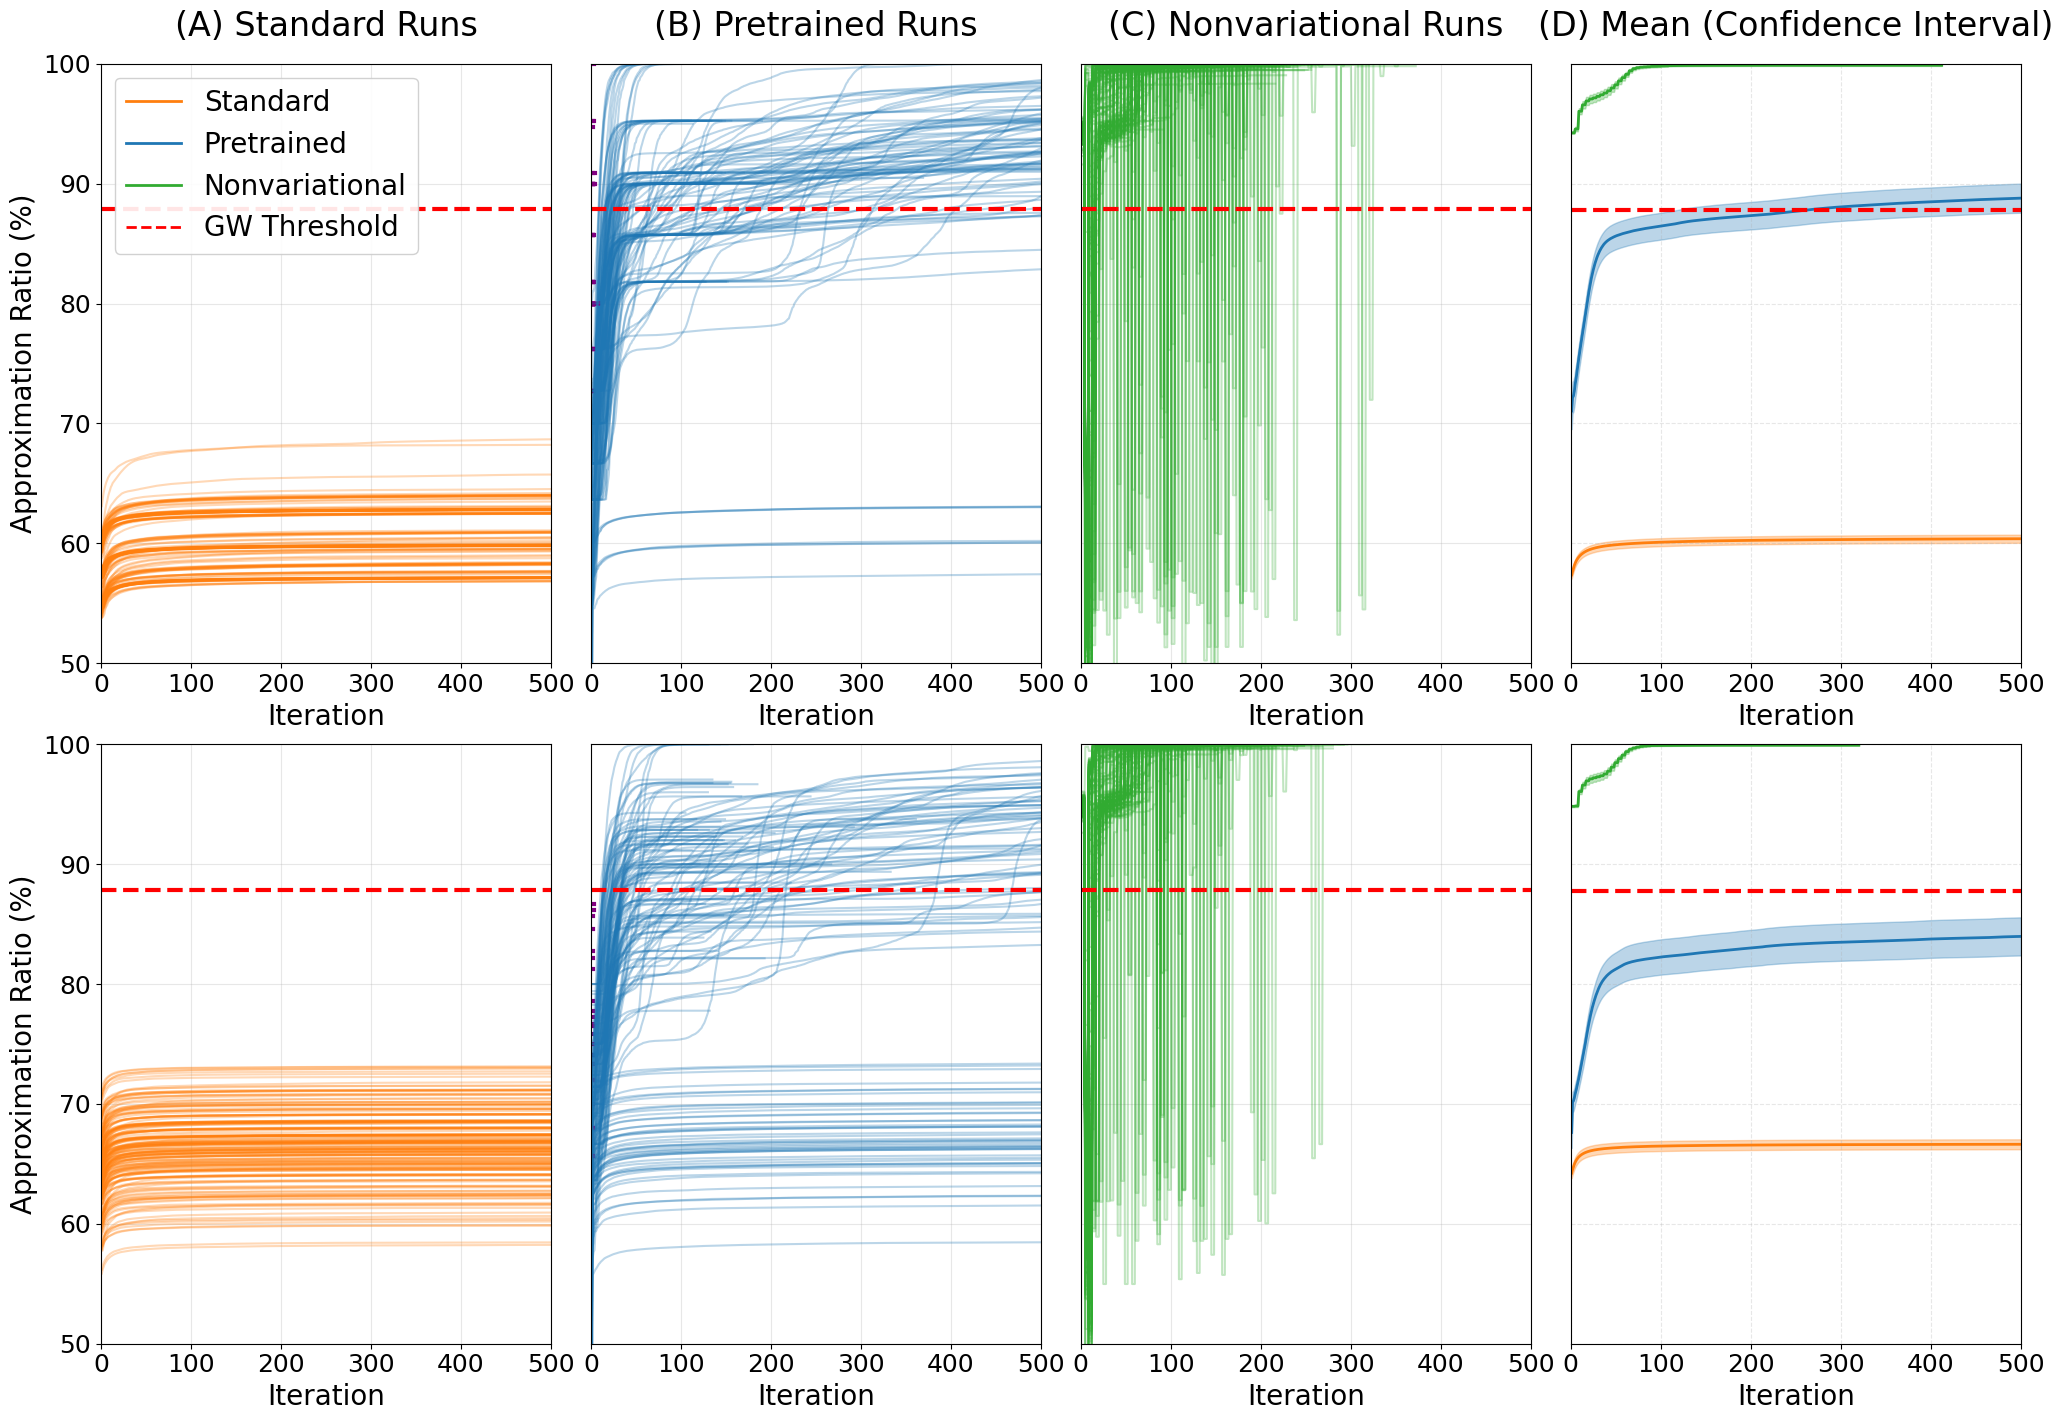

In [4]:
labels = ["Standard", "Pretrained", "Nonvariational"]
all_runs = [[Standard_3R_results['all_runs'],Path_Pretrained_3R_results['all_runs'],Nonvariational_3R_results['all_runs']],[Standard_ER_results['all_runs'],Path_Pretrained_ER_results['all_runs'],Nonvariational_ER_results['all_runs']]]
names = [ "3-Regular Graph","Erdros-Renyi Graph"]
rp2.plot_combined_horizontal(Standard_ER_results, Path_Pretrained_ER_results, Nonvariational_ER_results, Standard_3R_results, Path_Pretrained_3R_results, Nonvariational_3R_results, all_runs, names, labels)

In [17]:
# get the indices which give the local minima instances and the instances which dont improve
# upon the randomly initialised QAOA
indices_LM_3R = [i for i, x in enumerate(Path_Pretrained_3R_results['all_runs']) if len(x)<20]
indices_LM_ER = [i for i, x in enumerate(Path_Pretrained_ER_results['all_runs']) if len(x)<20]
indices_BP_3R = [i for i, x in enumerate(Path_Pretrained_3R_results['all_runs']) if round(np.abs(x[-1]-Standard_3R_results['all_runs'][i][-1]),3)<=0.01] 
indices_BP_ER = [i for i, x in enumerate(Path_Pretrained_ER_results['all_runs']) if round(np.abs(x[-1]-Standard_ER_results['all_runs'][i][-1]),3)<=0.01]
print(indices_BP_3R)

[52, 56, 95, 106, 124, 138, 179]


### Graph edit distance (GED)

In [ ]:
# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(18, 8),sharey=True)  # Increased height for better readability

# Define font sizes
title_fontsize = 22
label_fontsize = 20
tick_fontsize = 18

# First scatter plot on the left subplot
axs[0].scatter(
    np.array(Pretrained_3R_results["edit_dists"])[:, 0],
    100 * np.array(Pretrained_3R_results["edit_dists"])[:, 1],
    label='Successfully Trained'
)
axs[0].scatter(
    np.array(Pretrained_3R_results["edit_dists"])[indices_LM_3R, 0],
    100 *np.array(Pretrained_3R_results["edit_dists"])[indices_LM_3R, 1],
    label='Local Minima',color='purple'
)
axs[0].scatter(
    np.array(Pretrained_3R_results["edit_dists"])[indices_BP_3R, 0],
    100 *np.array(Pretrained_3R_results["edit_dists"])[indices_BP_3R, 1],
    label='No Improvement',color='orange'
)
axs[0].set_title(
    '(A) Pretrained QAOA on 3-Regular Graph',
    fontsize=title_fontsize
)
axs[0].set_xlabel('Graph edit distance', fontsize=label_fontsize)
axs[0].set_ylabel('Approximation ratio (%)', fontsize=label_fontsize)
axs[0].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[0].grid(True)
axs[0].axhline(y=87.8, color='red', linestyle='--',label="GW Threshold")  # Add horizontal line at 87.8
axs[0].legend(loc='lower left', fontsize=18)

# Second scatter plot on the right subplot
axs[1].scatter(
    np.array(Pretrained_ER_results["edit_dists"])[:, 0],
    100 * np.array(Pretrained_ER_results["edit_dists"])[:, 1],
    label='Edit Distance'
)
axs[1].scatter(
    np.array(Pretrained_ER_results["edit_dists"])[indices_LM_ER, 0],
    100 *np.array(Pretrained_ER_results["edit_dists"])[indices_LM_ER, 1],
    label='Edit Distance2',color='purple'
)
axs[1].scatter(
    np.array(Pretrained_ER_results["edit_dists"])[indices_BP_ER, 0],
    100 *np.array(Pretrained_ER_results["edit_dists"])[indices_BP_ER, 1],
    label='Edit Distance3',color='orange'
)
axs[1].set_title(
    '(B) Pretrained QAOA on ER Graph Instances',
    fontsize=title_fontsize
)
axs[1].set_xlabel('Graph edit distance', fontsize=label_fontsize)
# Disable y-axis ticks and labels
axs[1].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[1].grid(True)
axs[1].axhline(y=87.8, color='red', linestyle='--')  # Add horizontal line at 87.8

# Adjust layout to prevent overlap
plt.tight_layout()


### Solution similarity (Hamming distance)

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8),sharey=True)  # Increased height for better readability

# Define font sizes
title_fontsize = 22
label_fontsize = 20
tick_fontsize = 18

# First scatter plot on the left subplot
axs[0].scatter(
    np.array(Pretrained_3R_results['hamming_dists_min'])[:, 0],
    100 * np.array(Pretrained_3R_results['hamming_dists_min'])[:, 1],
    label="Successfully Trained"
)
axs[0].scatter(
    np.array(Pretrained_3R_results['hamming_dists_min'])[indices_LM_3R, 0],
    100 * np.array(Pretrained_3R_results['hamming_dists_min'])[indices_LM_3R, 1],
    label="Local Minima",color='purple'
)
axs[0].scatter(
    np.array(Pretrained_3R_results['hamming_dists_min'])[indices_BP_3R, 0],
    100 * np.array(Pretrained_3R_results['hamming_dists_min'])[indices_BP_3R, 1],
    label="No Improvement",color='orange'
)
axs[0].set_title(
    '(A) Pretrained QAOA on 3-Regular Graph Instances',
    fontsize=title_fontsize
)
axs[0].set_xlabel('Hamming Distance', fontsize=label_fontsize)
axs[0].set_ylabel('Approximation ratio (%)', fontsize=label_fontsize)
axs[0].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[0].grid(True)
axs[0].axhline(y=87.8, color='red', linestyle='--',label="GW Threshold")  # Add horizontal line at 87.8
axs[0].legend(loc='lower left', fontsize=18)

# Second scatter plot on the right subplot
axs[1].scatter(
    np.array(Pretrained_ER_results['hamming_dists_min'])[:, 0],
    100 * np.array(Pretrained_ER_results['hamming_dists_min'])[:, 1],
    label="Successfully Trained"
)
axs[1].scatter(
    np.array(Pretrained_ER_results['hamming_dists_min'])[indices_LM_ER, 0],
    100 * np.array(Pretrained_ER_results['hamming_dists_min'])[indices_LM_ER, 1],
    label="Local Minima",color='purple'
)
axs[1].scatter(
    np.array(Pretrained_ER_results['hamming_dists_min'])[indices_BP_ER, 0],
    100 * np.array(Pretrained_ER_results['hamming_dists_min'])[indices_BP_ER, 1],
    label="Barren Plateau",color='orange'
)
axs[1].set_title(
    '(B) Pretrained QAOA on ER Graph Instances',
    fontsize=title_fontsize
)
axs[1].set_xlabel('Hamming Distance', fontsize=label_fontsize)
# Disable y-axis ticks and labels
axs[1].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[1].grid(True)
axs[1].axhline(y=87.8, color='red', linestyle='--')  # Add horizontal line at 87.8

# Adjust layout to prevent overlap
plt.tight_layout()



## Section 4: Cost Distribution and Percentile of Path Graph Solution

In [ ]:
# gets the partition which solves MaxCut for the Path Graph
def PathPartion(n):
    string= [0,1]*(n//2)
    if n%2 !=0:
        string.append(0)
    return string

In [ ]:
# Set label and tick font sizes
label_fontsize = 15
tick_fontsize = 14

# Generate an Erdős-Rényi (ER) random graph
G = mQAOA.random_graph(16, G_type="random", weighted=False, p=0.3, seed=1)
# Get the quality vector
c_er = mQAOA.get_quality_vector(G)
# Calculate the mean of the quality vector
mean_c_er = np.mean(c_er)

# Generate a 3-regular graph
G = mQAOA.random_graph(16, G_type="3-regular", weighted=False, seed=42)
# Get the quality vector
c_reg = mQAOA.get_quality_vector(G)
# Calculate the mean of the quality vector
mean_c_reg = np.mean(c_reg)

# Create the histogram
plt.figure(figsize=(10, 6))
plt.hist(c_er, bins=100, edgecolor='black', alpha=0.7, label='ER Graph')
plt.hist(c_reg, bins=100, edgecolor='black', alpha=0.7, label='3-Regular Graph')

# Add vertical lines to highlight the means
plt.axvline(mean_c_er, color='red', linestyle='dashed', linewidth=2, label='ER Mean')
plt.axvline(mean_c_reg, color='black', linestyle='dashed', linewidth=2, label='3-Regular Mean')

# Adding labels and title
plt.xlabel('Cut Value', fontsize=label_fontsize)
plt.ylabel('Frequency', fontsize=label_fontsize)
plt.grid(True)

# Adjust tick font sizes
plt.xticks(fontsize=tick_fontsize)
plt.yticks(fontsize=tick_fontsize)

# Add a legend to distinguish the mean and percentile lines
plt.legend(fontsize=label_fontsize)

# Display the histogram
plt.show()


### Erdros-Renyi (Edge probability 30%) Percentile
This code demonstrates the percentile in which the random QAOA initialises in for 16 qubits, as well as the percentile which the pretrained model initialises in. The pretrained initital state is known to be fixed as the solution to the path graph, the alternating 01 state, and therefore does not need to be computed. This allows for the percentile to scalling to be effeicently found at varying qubit levels. For the random QAOA multiple empirical trials are run for only a single graph instance as it is computationally expensive (requires running the full circuit). These are seen to correspond to the analytical result, which is therefore used for the rest of the trials.

In [ ]:
# Define the number of qubits and trials for all runs
qubits =[6,8,10,12,14,16]
trials= 200

In [ ]:
#Empirical expected initial percentile for random QAOA of one graph instance at each problem size
# increase trial number to further approach the exact analytical value
p=n**2
all_trials = []
costs = []
for n in qubits:
    costs = []
    for t in range(50):
        G=QAOA.random_graph(n,G_type="random",weighted=False,seed=1,p=0.3) # fixed graph
        result0,c=Standard_QAOA(G,n,p)
        costs.append(result0)
    print("Mean cost accross total disribution: ",np.mean(c))
    print("Mean initial cost: ",np.mean(costs),"Variance in the costs: ",np.var(costs))

In [ ]:
# Calcualte mean cost (ie the vlaue at which the BP occurs) for the ER Graphs
Rmedian_ER_percentiles = []
Raverage_ER_percentiles = []
Rfraction_ER_above_55th = []
R_ER_std = []
means=[]
Rall_trials16_ER =[]
for n in qubits:
    p=n**2
    all_trials=[]
    bad_seeds =[]
    good_seeds =[]
    average_seeds=[]
    why_so_slow=[]
    costs=[]
    for t in range(trials):
        G=mQAOA.random_graph(n,G_type="random",weighted=False,seed=t,p=0.3)
        c=mQAOA.get_quality_vector(G)
        if max(c) == 0:
            continue
        expected_c = sum(c)/(2**n) # from analytical solution
        means.append(expected_c/max(c))
        percentile=stats.percentileofscore(c, expected_c,kind="rank") 
        all_trials.append(percentile)
    if n==16:
        Rall_trials16_ER=all_trials
    print("For n=",n)
    print("Average percentile: ",np.mean(all_trials)," Median percentile: ", np.median(all_trials), "std: ", np.std(all_trials), "max: ", max(all_trials), "min: ", min(all_trials))
    Rmedian_ER_percentiles.append(np.median(all_trials))
    Raverage_ER_percentiles.append(np.mean(all_trials))
    R_ER_std.append(np.std(all_trials))
    print("Average expected approximation ratio (%): ",100*np.mean(means), "std: ", 100*np.std(means), "max: ",100*max(means), "min: ", 100*min(means))
    

In [ ]:
def split_above_random(values):
    # Sort the list
    sorted_values = sorted(values)
    
    # Determine the indices for the 30% split
    n = len(sorted_values)

    left_index = bisect.bisect_right(sorted_values, 49.43)

    
    return ((n-left_index)/n)*100

In [ ]:
# Calcualte the percentile at which the path graph occurs for the ER Graphs
Pmedian_ER_percentiles = []
Paverage_ER_percentiles = []
Pfraction_ER_above_55th = []
P_ER_std = []
Pfraction_above_47th_ER = []
Pall_trials16_ER=[]
compare_to_random=[]
for n in qubits:
    p=n**2
    all_trials=[]
    for t in range(trials):
        G=mQAOA.random_graph(n,G_type="random",weighted=False,seed=t,p=0.3)
        c=mQAOA.get_quality_vector(G)
        if max(c) == 0:
            continue
        p=stats.percentileofscore(c, c[to_int(PathPartion(n))],kind="rank")
        all_trials.append(p)
    if n==16:
        Pall_trials16_ER=all_trials
    print("For n=",n)
    print("Average percentile: ",np.mean(all_trials)," Median percentile: ", np.median(all_trials), "std: ", np.std(all_trials),"max: ", max(all_trials), "min: ", min(all_trials))
    Pmedian_ER_percentiles.append(np.median(all_trials))
    Paverage_ER_percentiles.append(np.mean(all_trials))
    P_ER_std.append(np.std(all_trials))
    print("Percentage of trials above Random Start: ",split_above_random(all_trials))
    Pfraction_above_47th_ER.append(split_above_random(all_trials))

### 3-Regular Percentiles:

In [ ]:
# Percentile of the mean value (ie the value at which the BP occurs) for the 3-Regular Graphs
Rmedian_3R_percentiles = []
Raverage_3R_percentiles = []
Rfraction_3R_above_55th = []
R_3R_std = []
Rall_trials16_3R = []
for n in qubits:
    p=n**2
    all_trials=[]
    bad_seeds =[]
    good_seeds =[]
    average_seeds=[]
    why_so_slow=[]
    costs=[]
    for t in range(trials):
        G=mQAOA.random_graph(n,G_type="3-regular",weighted=False,seed=t)
        c=mQAOA.get_quality_vector(G)
        if max(c) == 0:
            continue
        percentile=stats.percentileofscore(c, sum(c)/(2**n),kind="rank")
        percentile
        all_trials.append(percentile)
    if n==16:
        Rall_trials16_3R = all_trials
    print("For n=",n)
    print("Average percentile: ",np.mean(all_trials)," Median percentile: ", np.median(all_trials), "std: ", np.std(all_trials), "max: ", max(all_trials), "min: ", min(all_trials))
    Rmedian_3R_percentiles.append(np.median(all_trials))
    Raverage_3R_percentiles.append(np.mean(all_trials))
    R_3R_std.append(np.std(all_trials))

In [ ]:
def split_above_random(values):
    # Sort the list
    sorted_values = sorted(values)
    
    # Determine the indices for the 30% split
    n = len(sorted_values)

    left_index = bisect.bisect_right(sorted_values, 49.43)

    
    return ((n-left_index)/n)*100

In [ ]:
# percentile of the pathe graph solution for the 3-Regular Graphs
Pmedian_3R_percentiles = []
Paverage_3R_percentiles = []
Pfraction_3R_above_55th = []
P_3R_std = []
Pfraction_above_47th = []
Pall_trials16_3R =[]
for n in qubits:
    all_trials=[]
    bad_seeds =[]
    good_seeds =[]
    average_seeds=[]
    costs=[]
    for t in range(trials):
        G=mQAOA.random_graph(n,G_type="3-regular",weighted=False,seed=t)
        c=mQAOA.get_quality_vector(G)
        if max(c) == 0:
            continue
        p=stats.percentileofscore(c, c[to_int(PathPartion(n))],kind="rank")
        all_trials.append(p)
    if n==16:
        Pall_trials16_3R=all_trials
    print("For n=",n)
    print("Average percentile: ",np.mean(all_trials)," Median percentile: ", np.median(all_trials), "std: ", np.std(all_trials),"max: ", max(all_trials), "min: ", min(all_trials))
    Pmedian_3R_percentiles.append(np.median(all_trials))
    Paverage_3R_percentiles.append(np.mean(all_trials))
    P_3R_std.append(np.std(all_trials))
    print("Percentage of trials above Random Start: ",split_above_random(all_trials))
    Pfraction_above_47th.append(split_above_random(all_trials))

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# First plot: 3-Regular Graphs
ax1.errorbar(
    qubits, 
    Paverage_3R_percentiles, 
    yerr = P_3R_std, 
    fmt = 'o',  
    capsize= 5,  
    label ='Pretrained QAOA',
    ecolor='gray',  
    linestyle='-',   
    markerfacecolor='blue'
)

ax1.errorbar(
    qubits, 
    Raverage_3R_percentiles, 
    yerr=R_3R_std, 
    fmt='o',  
    capsize=5,  
    label='Random QAOA',
    ecolor='gray',  
    linestyle='-',   
    markerfacecolor='blue'
)

ax1.set_xlabel('Number of Qubits (n)',fontsize=18)
ax1.set_ylabel('Percentile in Graph Gost Distribution',fontsize=18)
ax1.set_title('(A)',fontsize=18)
ax1.legend(fontsize=18,loc='upper left')
ax1.grid(True)
ax1.tick_params(axis='both', which='major', labelsize=16)

# Second plot: Erdros-Renyi Graphs
ax2.errorbar(
    qubits, 
    Paverage_ER_percentiles, 
    yerr = P_ER_std, 
    fmt = 'o',  
    capsize= 5,  
    label ='Pretrained QAOA',
    ecolor='gray',  
    linestyle='-',   
    markerfacecolor='blue'
)

ax2.errorbar(
    qubits, 
    Raverage_ER_percentiles, 
    yerr=R_ER_std, 
    fmt='o',  
    capsize=5,  
    label='Random QAOA',
    ecolor='gray',  
    linestyle='-',   
    markerfacecolor='blue'
)

ax2.set_xlabel('Number of Qubits (n)',fontsize=18)
ax2.set_ylabel('Percentile in Graph Gost Distribution',fontsize=18)
ax2.set_title('(B)',fontsize=18)
ax2.tick_params(axis='both', which='major', labelsize=16)
ax2.grid(True)

plt.tight_layout()
plt.show()


## Section 5: Relation between Initial Percentile and Pretraining Success

In [ ]:
def process_percentiles(folder_path):
    # Initialize lists to store percentiles and bad instances
    percentiles = []
    # List to store all normalized runs
    all_normalized_runs = []
    def numerical_sort(value):
    # Extract numbers from the filename and convert them to integers
        return int(''.join(filter(str.isdigit, value)))
    # Iterate through each file in the folder
    txt_files = sorted([f for f in os.listdir(folder_path) if f.endswith(".txt")], key=numerical_sort)
    # Iterate through each file and its corresponding data
    for idx, filename in enumerate(txt_files):
        filepath = os.path.join(folder_path, filename)
        
        # Initialize variables to store data
        maxcut = None
        qaoa_values = []
        percentile = None  # Variable to store percentile
        
        with open(filepath, 'r') as file:
            for line in file:
                # Extract the percentile from the first line (it's usually there)
                if line.startswith("200 iters for seed") or line.startswith("500 iters for seed") and "percentile" in line:
                    try:
                        # Split the line using 'percentile' and extract the number
                        l1 = line.split("the")
                        percentile_str = l1[1].split("percentile")[0].strip()
                        if percentile_str:  # Ensure there's something to convert
                            percentile = float(percentile_str)
                        l2 = line.split("seed")
                        seed = l2[1].split("on")[0].strip()
                        s=int(seed)
                    except (IndexError, ValueError):
                        print(f"Warning: Could not parse percentile in file {filename}")
                        percentile = None

                # Extract the Maxcut value
                elif line.startswith(" Maxcut:"):
                    try:
                        maxcut = float(line.split()[1].strip(','))
                    except (IndexError, ValueError):
                        print(f"Warning: Could not parse Maxcut in file {filename}")
                        maxcut = None
                        
                # Collect QAOA values if the line starts with a number (i.e., it's not metadata)
                elif line.strip().replace('-', '').replace('.', '').isdigit():
                    try:
                        qaoa_values.append(-float(line.strip()))
                    except ValueError:
                        print(f"Warning: Could not parse QAOA value in file {filename}")

        # Normalize QAOA values by Maxcut and prepare iterations
        normalized_values = [val / maxcut for val in qaoa_values]
        
            
        percentiles.append([percentile,normalized_values[-1],s])
    return percentiles

## Directly compare the individual trial runs

In [ ]:
# Find the seeds which are above the percentile at which the concentration occurs
above_concentration_ER=[1 if a >=b else 0 for a, b in zip(Pall_trials16_ER, Rall_trials16_ER)]
above_concentration_3R=[1 if a >=b else 0 for a, b in zip(Pall_trials16_3R, Rall_trials16_3R)]
seeds_above_concentration_ER = [index for index, value in enumerate(above_concentration_ER) if value == 1]
seeds_above_concentration_3R = [index for index, value in enumerate(above_concentration_3R) if value == 1]
seeds_below_concentration_ER = [index for index, value in enumerate(above_concentration_ER) if value == 0]
seeds_below_concentration_3R = [index for index, value in enumerate(above_concentration_3R) if value == 0]

# Find the seeds identified previously as being unable to improve on random initialisation
seeds_BP_ER=np.array(Pretrained_ER_results['seeds'])[indices_BP_ER]
seeds_BP_3R=np.array(Pretrained_3R_results['seeds'])[indices_BP_3R]

In [ ]:
# for the 3R graphs they are exactly equal
set(seeds_BP_3R)==set(seeds_below_concentration_3R),len(seeds_BP_3R)

In [ ]:
# Three exceptions for the ER graphs
seeds_BP_ER 
seeds_below_concentration_ER

EqualR_instances_with_initP_above= set(seeds_BP_ER ) - set(seeds_below_concentration_ER)

Imporved_instances_with_initP_below = set(seeds_below_concentration_ER) - set(seeds_BP_ER)

print("Total instances which started below the percentile at which the concentration occurs:", len(seeds_below_concentration_ER))
print("Instances which did not improve on random and started above:", EqualR_instances_with_initP_above)
print("Instances which improved on random and started below:", Imporved_instances_with_initP_below )

In [ ]:
# load the data from the files
percentiles_3R = process_percentiles("FINAL_3R_PRETRAINED")
percentiles_ER = process_percentiles("FINAL_ER30_PRETRAINED")

In [ ]:
# the three instances which are exceptions to the general trend
for i in range(len(percentiles_ER)):
    if np.array(percentiles_ER)[i,0]<46 and np.array(percentiles_ER)[i,1]>0.8:
        print(np.array(percentiles_ER)[i,0],np.array(percentiles_ER)[i,1],"seed: ",np.array(percentiles_ER)[i,2])

In [ ]:
# mean achieved approx ratio for instances "above concentration", which for optimiser that is minimising means below the BP
start_below=np.array(percentiles_ER)[seeds_above_concentration_ER,1]
start_above=np.array(percentiles_ER)[seeds_below_concentration_ER,1]
print("The mean final achieved approxiamtion ratio for ER instances initialised below the BP:",np.mean(start_below))
print("The mean final achieved approxiamtion ratio for ER instances initialised below the BP:",np.mean(start_above))
total=0
for i in range(len(start_below)):
    if np.array(start_below)[i]>=0.8786:
        total+=1
print("Fraction of ER instances below BP which also surpassed the GW threshold: ", total/len(start_below))
total=0
for i in range(len(start_above)):
    if np.array(start_above)[i]>=0.8786:
        total+=1
print("Fraction of ER instances above BP which also surpassed the GW threshold: ", total/len(start_above))

In [ ]:
# mean achieved approx ratio for instances "above concentration", which for optimiser that is minimising means below the BP
start_below=np.array(percentiles_3R)[seeds_above_concentration_3R,1]
start_above=np.array(percentiles_3R)[seeds_below_concentration_3R,1]
print("The mean final achieved approxiamtion ratio for 3R instances initialised below the BP:",np.mean(start_below))
print("The mean final achieved approxiamtion ratio for 3R instances initialised below the BP:",np.mean(start_above))
total=0
for i in range(len(start_below)):
    if np.array(start_below)[i]>=0.8786:
        total+=1
print("Fraction of 3R instances below BP which also surpassed the GW threshold: ", total/len(start_below))
total=0
for i in range(len(start_above)):
    if np.array(start_above)[i]>=0.8786:
        total+=1
print("Fraction of 3R instances above BP which also surpassed the GW threshold: ", total/len(start_above))
for i in range(len(start_below)):
    if np.array(start_below)[i]>=0.9326:
        total+=1
print("Fraction of 3R instances below BP which also surpassed the best classical (note 3-regular have higher threshold than GW): ", total/len(start_below))

## Plot to highlight the clear transition in performance

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8),sharey=True)  # Increased height for better readability

# Define font sizes
title_fontsize = 20
label_fontsize = 18
tick_fontsize = 18

seeds_LM_ER=np.array(Pretrained_ER_results['seeds'])[indices_LM_ER]
seeds_LM_3R=np.array(Pretrained_3R_results['seeds'])[indices_LM_3R]
# First scatter plot on the left subplot
axs[0].scatter(
    np.array(percentiles_3R)[:,0],
    100*np.array(percentiles_3R)[:,1],
    label="Successfully Trained"
)
axs[0].scatter(
    np.array(percentiles_3R)[seeds_BP_3R,0],
    100*np.array(percentiles_3R)[seeds_BP_3R,1],
    color='orange',
    label="No Improvement"
)
axs[0].scatter(
    np.array(percentiles_3R)[seeds_LM_3R,0],
    100*np.array(percentiles_3R)[seeds_LM_3R,1],
    color='purple',
    label="Local Minima"
)
axs[0].set_title(
    '(A) Pretrained QAOA on 3-Regular Graph Instances',
    fontsize=title_fontsize
)
axs[0].set_xlabel('Initial Percentile', fontsize=label_fontsize)
axs[0].set_ylabel('Approximation Ratio (%)', fontsize=label_fontsize)
axs[0].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[0].grid(True)
axs[0].axhline(y=87.8, color='red', linestyle='--',label="GW threshold")  # Add horizontal line at 87.8
axs[0].axvline(x=np.mean(Rall_trials16_3R), color='black', linestyle='--', label="Mean Percentile of Concentration") 
axs[0].legend(loc='lower right', fontsize=18)

# Second scatter plot on the right subplot
axs[1].scatter(
    np.array(percentiles_ER)[:,0],
    100*np.array(percentiles_ER)[:,1]
)
axs[1].scatter(
    np.array(percentiles_ER)[seeds_BP_ER,0],
    100*np.array(percentiles_ER)[seeds_BP_ER,1],
    color='orange'
)
axs[1].scatter(
    np.array(percentiles_ER)[seeds_LM_ER,0],
    100*np.array(percentiles_ER)[seeds_LM_ER,1],
    color='purple'
)

axs[1].set_title(
    '(B) Pretrained QAOA on ER Graph Instances',
    fontsize=title_fontsize
)
axs[1].set_xlabel('Initial Percentile', fontsize=label_fontsize)
axs[1].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[1].grid(True)
axs[1].axhline(y=87.8, color='red', linestyle='--',label="GW threshold")  # Add horizontal line at 87.8
axs[1].axvline(x=np.mean(Rall_trials16_ER), color='black', linestyle='--',label="Percentile at which BP occurs") 


# Adjust layout to prevent overlap
plt.tight_layout()


### Additional plot highlighting the lack of relation between the metrics and performance
did not use in thesis

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

# Define font sizes
title_fontsize = 20
label_fontsize = 16
tick_fontsize = 14


# First scatter plot on the left subplot (Pretrained QAOA on 3-Regular Graph)
sc1 = axs[0].scatter(
    np.array(percentiles_3R)[:,0],  # x-axis (Initial Percentile)
    100*np.array(percentiles_3R)[:,1],  # y-axis (Approximation Ratio)
    c=np.array(Pretrained_ER_results['edit_dists'])[:, 0],  # Colour map by Hamming Distance
    cmap='viridis'  # Colour map style
)
axs[0].set_title('Pretrained QAOA on 3-Regular Graph', fontsize=title_fontsize)
axs[0].set_xlabel('Initial Percentile', fontsize=label_fontsize)
axs[0].set_ylabel('Approximation Ratio (%)', fontsize=label_fontsize)
axs[0].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[0].grid(True)
axs[0].axhline(y=87.8, color='red', linestyle='--')  # Horizontal line at 87.8
axs[0].axvline(x=49.4, color='black', linestyle='--')  # Vertical line at 49.4

# Add colorbar for the first plot
cbar1 = fig.colorbar(sc1, ax=axs[0])
cbar1.set_label('Hamming Distance', fontsize=label_fontsize)

# Second scatter plot on the right subplot (Pretrained QAOA on Erdros-Renyi Graph)
sc2 = axs[1].scatter(
    np.array(percentiles_ER)[:,0],  # x-axis (Initial Percentile)
    100*np.array(percentiles_ER)[:,1],  # y-axis (Approximation Ratio)
    c=np.array(Pretrained_ER_results['edit_dists'])[:, 0],  # Colour map by Hamming Distance
    cmap='plasma'  # Colour map style
)
axs[1].set_title('Pretrained QAOA on Erdros-Renyi Graph', fontsize=title_fontsize)
axs[1].set_xlabel('Initial Percentile', fontsize=label_fontsize)
axs[1].set_ylabel('Approximation Ratio (%)', fontsize=label_fontsize)
axs[1].tick_params(axis='both', which='major', labelsize=tick_fontsize)
axs[1].grid(True)
axs[1].axhline(y=87.8, color='red', linestyle='--')  # Horizontal line at 87.8
axs[1].axvline(x=45.5, color='black', linestyle='--')  # Vertical line at 45.5

# Add colorbar for the second plot
cbar2 = fig.colorbar(sc2, ax=axs[1])
cbar2.set_label('Hamming Distance', fontsize=label_fontsize)

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plots
plt.show()


## Section 6: Conjecture 2: Demonstrating different parameters may be trained to.
The pretraining was run on Setonix 5 times until convergence. See File.py for example implimentation. The determined parameters were then run on 3 instances. The collected data and initial parameters are stored in the folders Trial_Different_Params and Different_Params respectively.

In [ ]:
# first some data processing is performed
import pandas as pd

# Define the directory containing the parameter files
directory = 'different_params'

# Initialize an empty list to store the data
data_list = []

# Iterate over all files in the directory
for filename in os.listdir(directory):
    # Check if the file matches the expected pattern
    if filename.startswith('Graph_Parameters16_256_trial_') and filename.endswith('.npz'):
        # Extract the trial number from the filename
        trial_number_str = filename.split('_')[-1].replace('.npz', '')
        trial_number = int(trial_number_str)
        
        # Load the .npz file
        data = np.load(os.path.join(directory, filename))
        parameters = [data[key] for key in data]
        gamma = np.array(parameters[0])
        beta = np.array(parameters[1])
        
        # Demonstrate the convergence
        # Ensure that the QAOA module and functions are properly imported
        # from your QAOA implementation
        GP = QAOA.random_graph(16, G_type="path", weighted=False, seed=1, p=0.3)
        Q, qc, gamma_params, time_params = QAOA.set_up_sim(16, 256, GP)
        result = QAOA.expectation(Q, qc, GP, gamma_params, time_params, gamma, beta, 256, optimize=False, return_max_prob=True)
        
        # Calculate the approximation ratio and probability on the optimal solution
        approximation_ratio = 100*result[0] / 15  # Replace 15 with the optimal MaxCut value if different
        probability_on_optimal = result[1] * 100  # Convert to percentage
        
        print(f"The approximation ratio is: {approximation_ratio} with {probability_on_optimal}% of the probability on the optimal solution")
        
        # Get the first 2 values of gamma and beta
        gamma_first2 = gamma[:2]
        beta_first2 = beta[:2]
        
        # Prepare a dictionary to hold the data
        data_dict = {'Trial': trial_number}
        # Add gamma and beta values to the dictionary, rounding them
        for i in range(2):
            data_dict[f'Gamma_{i+1}'] = round(gamma_first2[i], 6)
            data_dict[f'Beta_{i+1}'] = round(beta_first2[i], 6)
        
        # Add approximation ratio and probability to the dictionary
        data_dict['Approximation_Ratio'] = round(approximation_ratio, 6)
        data_dict['Probability_on_Optimal'] = round(probability_on_optimal, 6)
        
        # Append the dictionary to the data list
        data_list.append(data_dict)

# Create a DataFrame from the data list
df = pd.DataFrame(data_list)

# Reorder data so the original parameter set is given by 0


df['Trial'] = df['Trial'] + 1

trial_5_row = df[df['Trial'] == 6]


df.loc[df['Trial'] == 6, 'Trial'] = 0


df = df.sort_values('Trial').reset_index(drop=True)

print(df)



In [ ]:
# Convert to LaTex table for thesis
df.rename(columns={
    'Trial': 'Trial',
    'Gamma_1': r'\ensuremath{\gamma^{P}_{1}}',
    'Gamma_2': r'\ensuremath{\gamma^{P}_{2}}',
    'Beta_1': r'\ensuremath{\beta_{1}}',
    'Beta_2': r'\ensuremath{\beta_{2}}',
    'Approximation_Ratio': 'Approx. Ratio (\%)',
    'Probability_on_Optimal': 'Prob. on Optimal (\%)'
}, inplace=True)



latex_table = df.to_latex(
    index=False,
    float_format="%.6f",
    column_format="rcccccc",
    header=True,
    escape=False  
)


with open('gamma_beta_table.tex', 'w') as f:
    f.write(latex_table)


In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.pyplot as plt
import numpy as np
import os

# Folder containing the text files
folder = "Trial_Different_Params"
titles = {1: "(A)", 2: "(B)", 3: "(C)"}

# functions to extract data, there are two as the original data was formatted differently to the parameter trial runs
def extract_data_from_file(filepath):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    trial = None
    max_cut = None
    cut_values = []
    
    # Extracting trial number, MaxCut, and cut values from the file
    for line in lines:
        if line.startswith(" TRIAL:"):
            trial = int(line.split(":")[1].strip())
        elif "Maxcut" in line:

            max_cut = float(line.split("Maxcut:")[1].split(",")[0].strip())
        elif line.startswith("-"):
            # Extracting cut values (stored as negative values, hence take negative of them)
            cut_values.append(-float(line.strip()))
    
    return trial, max_cut, cut_values


def extract_data_from_file2(filepath):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    max_cut = None
    cut_values = []
    
    # Extracting MaxCut and cut values from the file
    for line in lines:
        if "Maxcut" in line:

            max_cut = float(line.split("Maxcut:")[1].split(",")[0].strip())
        elif line.startswith("-"):
            # Extracting cut values (stored as negative values, hence take negative of them)
            cut_values.append(-float(line.strip()))
    
    return max_cut, cut_values

# Collecting data from the folder
data = {}
for filename in os.listdir(folder):
    if filename.endswith(".txt"):
        parts = filename.split("_")
        seed = int(parts[4])
        trial, max_cut, cut_values = extract_data_from_file(os.path.join(folder, filename))
        
        if seed not in data:
            data[seed] = {}
        
        # Storing max_cut and cut_values together
        data[seed][trial] = {'max_cut': max_cut, 'cut_values': cut_values}

for seed in [6, 37, 116]: 
    filepath = os.path.join('FINAL_ER30_PRETRAINED', f"P_Seed_{seed}_Qubits_16_Layers_256.txt")

    max_cut, cut_values = extract_data_from_file2(filepath)
        
    # Storing max_cut and cut_values together
    data[seed][6] = {'max_cut': max_cut, 'cut_values': cut_values}

seeds = sorted(data.keys())


In [ ]:
titles = {1: "(A)", 2: "(B)", 3: "(C)"}

# Plotting data
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
seeds = sorted(data.keys())

for i, seed in enumerate(seeds):
    subplot_index = 2 if i == 1 else 1 if i == 2 else i
    
    for trial in sorted(data[seed].keys()):
        iterations = range(len(data[seed][trial]['cut_values']))
        max_cut = data[seed][trial]['max_cut']
        cut_values = np.array(data[seed][trial]['cut_values'])
        
        # Calculate approximation ratio
        approximation_ratio = cut_values / max_cut
        
        # Plot the approximation ratio
        if trial < 6:
            axes[subplot_index].plot(iterations, 100 * approximation_ratio, label=f"Trial {trial+1}", alpha=0.6, linewidth=4)
        else:
            axes[subplot_index].plot(iterations, 100 * approximation_ratio, label=f"Original Trial", alpha=0.6, linewidth=4)
    
    axes[subplot_index].set_title(titles[subplot_index+1], fontsize=20)
    axes[subplot_index].set_xlabel("Iteration", fontsize=20)
    axes[subplot_index].tick_params(axis='both', which='major', labelsize=18)  # Increase tick label font size
    axes[subplot_index].grid(True)
    if subplot_index == 2:
        axes[subplot_index].legend(fontsize=20, loc='lower right')
    axes[subplot_index].axhline(y=87.8, color='red', linestyle='--', linewidth=2)  # Add horizontal line at 87.8
    
    # For the third subplot (now subplot_index 1, corresponding to seed 6), add an inset zoom on the first few iterations
    if subplot_index == 1:
        # Creating an inset axes in the second subplot (formerly third)
        ax_inset = inset_axes(axes[subplot_index], width="40%", height="40%", loc="lower right", borderpad=4)

        # Zooming in on the first two iterations
        for trial in sorted(data[seed].keys()):
            iterations = range(len(data[seed][trial]['cut_values']))
            cut_values = np.array(data[seed][trial]['cut_values'])
            approximation_ratio = cut_values / max_cut

            # Plot the zoomed-in approximation ratio for the first two iterations
            ax_inset.plot(iterations[:3], 100 * approximation_ratio[:3], label=f"Trial {trial}", linewidth=4, alpha=0.5)
        
        ax_inset.set_xlim(0, 2)  # Limiting x-axis to the first 2 iterations
        ax_inset.set_ylim(74.9, 75.05)  # Adjust y-axis limits to show approximation ratio better
        ax_inset.set_title("First 2 Iterations", fontsize=15)
        ax_inset.grid(True)

axes[0].set_ylabel("Approximation Ratio (%)", fontsize=20)

plt.tight_layout()
plt.show()


In [ ]:
titles = {1: "(A)", 2: "(B)", 3: "(C)"}

# Increase figure size
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)
seeds = sorted(data.keys())

for i, seed in enumerate(seeds):
    subplot_index = 2 if i == 1 else 1 if i == 2 else i
    
    for trial in sorted(data[seed].keys()):
        iterations = range(len(data[seed][trial]['cut_values']))
        max_cut = data[seed][trial]['max_cut']
        cut_values = np.array(data[seed][trial]['cut_values'])
        
        # Calculate approximation ratio
        approximation_ratio = cut_values / max_cut
        
        # Plot the approximation ratio
        if trial < 6:
            axes[subplot_index].plot(iterations, 100 * approximation_ratio, label=f"Trial {trial+1}", alpha=0.6, linewidth=4)
        else:
            axes[subplot_index].plot(iterations, 100 * approximation_ratio, label=f"Original Trial", alpha=0.6, linewidth=4)
    
    axes[subplot_index].set_title(titles[subplot_index+1], fontsize=24)  # Increase title font size
    axes[subplot_index].set_xlabel("Iteration", fontsize=22)  # Increase x-axis label font size
    axes[subplot_index].tick_params(axis='both', which='major', labelsize=20)  # Increase tick label font size
    axes[subplot_index].grid(True)
    if subplot_index == 2:
        axes[subplot_index].legend(fontsize=20, loc='lower right')
    axes[subplot_index].axhline(y=87.8, color='red', linestyle='--', linewidth=2)  # Add horizontal line at 87.8
    
    # For the second subplot, add an inset zoom on the first few iterations
    if subplot_index == 1:
        ax_inset = inset_axes(axes[subplot_index], width="40%", height="40%", loc="lower right", borderpad=4)

        for trial in sorted(data[seed].keys()):
            iterations = range(len(data[seed][trial]['cut_values']))
            cut_values = np.array(data[seed][trial]['cut_values'])
            approximation_ratio = cut_values / max_cut

            ax_inset.plot(iterations[:3], 100 * approximation_ratio[:3], label=f"Trial {trial}", linewidth=4, alpha=0.5)
        
        ax_inset.set_xlim(0, 2)
        ax_inset.set_ylim(74.98, 75.02)
        ax_inset.set_title("First 2 Iterations", fontsize=18)  # Adjust inset title font size
        ax_inset.grid(True)

axes[0].set_ylabel("Approximation Ratio (%)", fontsize=22)  # Increase y-axis label font size

# Increase spacing between subplots
plt.subplots_adjust(wspace=0.3)

plt.tight_layout()
plt.show()


## Section 7: Simple Demonstration that the average cut of all 50/50 partitions is typically better than all partions

In [ ]:
def generate_50_50_partitions(n, current_string='', num_zeros=0, num_ones=0):
    if len(current_string) == n:
        if num_zeros == num_ones:
            return [int(current_string, 2)]
        else:
            return []
    
    result = []
    
    if num_zeros < n // 2:
        result += generate_50_50_partitions(n, current_string + '0', num_zeros + 1, num_ones)
    
    if num_ones < n // 2:
        result += generate_50_50_partitions(n, current_string + '1', num_zeros, num_ones + 1)
    
    return result

# Example usage
n = 16
bit_strings_integers = generate_50_50_partitions(n)


In [ ]:
trials=200
import time
n=16
all_info=[]
all_trials=[]
all_trials2=[]
all_trials3=[]
bad_seeds =[]
good_seeds =[]
median_seeds=[]
why_so_slow=[]
count=0
bit_strings_integers = generate_50_50_partitions(n)
for i in range(trials):
    then=time.time()
    G = mQAOA.random_graph(n,G_type="random",weighted=False,seed=i)
    c=mQAOA.get_quality_vector(G)
    why_so_slow.append(time.time()-then)
    if max(c) == 0:
        continue
    p=stats.percentileofscore(c, c[to_int(PathPartion(n))],kind="rank")
    ideal_c = np.mean(c[bit_strings_integers])
    p2 = stats.percentileofscore(c, ideal_c,kind="rank")

    #if p >=99.9 and n>=10:
     #   print(n,i)
    all_trials.append(p)
    all_trials2.append(p2)
    all_info.append([i,p])
    if p<=10:
        bad_seeds.append([i,p])
    if p<=68 and p>=67:
        median_seeds.append([i,p])
    if int(p)  < 49 and n>=10:
        good_seeds.append([i,p])
print("Took ",np.sum(why_so_slow)," for ",n)
print("Count: ",count)
print("Average percentile PATH: ",np.mean(all_trials)," Median percentile: ", np.median(all_trials)," Std: ",np.std(all_trials))
print("Average percentile COMPLETE: ",np.mean(all_trials2)," Median percentile: ", np.median(all_trials2)," Std: ",np.std(all_trials2))
print("Smallest Complete percentile: ",min(all_trials2))
